<a href="https://colab.research.google.com/github/Haritsukeru/Machine-Learn/blob/main/%D0%9B%D0%A03_%D0%93%D1%83%D0%BB%D0%B0%D0%BA_%D0%A4%D0%86%D0%A2_3_12_ipynb.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Лабораторна робота 3. Машинне навчання
## Регресія: прогнозування вартості нерухомості

**Мета роботи:** виконати первинний аналіз даних, побудувати кілька моделей регресії, оцінити їхню якість та виконати підбір гіперпараметрів для моделі Random Forest.

### Датасет
Можна використати один із двох способів завантаження даних:

1. Завантажити файл з Google Drive:
https://drive.google.com/file/d/1u_-3X05st6uvrgQB1qNLyE8a7QjTJjvd/view?usp=sharing

2. Завантажити датасет з Kaggle:
https://www.kaggle.com/datasets/prokshitha/home-value-insights

> Посилання та вміст датасету на зовнішніх платформах можуть змінюватися.

## 1. Імпорт бібліотек
Імпортуйте бібліотеки, необхідні для роботи з даними, візуалізації та числових обчислень.

In [9]:
# Ваш код:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="darkgrid")

## 2. Завантаження даних
Завантажте файл двома способами.

### Варіант 1. Завантаження файлу з комп’ютера
Завантажте CSV-файл у середовище Colab.

In [10]:
from google.colab import files
import io
import pandas as pd

uploaded = files.upload()

file_name = list(uploaded.keys())[0]

df = pd.read_csv(io.BytesIO(uploaded[file_name]))

df.head()


Saving house_price_regression_dataset.csv to house_price_regression_dataset (2).csv


,Square_Footage,Num_Bedrooms,Num_Bathrooms,Year_Built,Lot_Size,Garage_Size,Neighborhood_Quality,House_Price
0,1360,2,1,1981,0.599637,0,5,2.623829e+05
1,4272,3,3,2016,4.753014,1,6,9.852609e+05
2,3592,1,2,2016,3.634823,0,9,7.779774e+05
3,966,1,2,1977,2.730667,1,8,2.296989e+05
4,4926,2,1,1993,4.699073,0,8,1.041741e+06


### Варіант 2. Завантаження датасету з Kaggle
Завантажте датасет безпосередньо з Kaggle та прочитайте CSV-файл у DataFrame `df`.

In [11]:
import kagglehub

path = kagglehub.dataset_download("prokshitha/home-value-insights")

print("Path to dataset files:", path)


Using Colab cache for faster access to the 'home-value-insights' dataset.
Path to dataset files: /kaggle/input/home-value-insights


In [12]:
import os
import pandas as pd

dataset_path = "/kaggle/input/home-value-insights"

csv_files = [f for f in os.listdir(dataset_path) if f.endswith('.csv')]
full_path = os.path.join(dataset_path, csv_files[0])

df = pd.read_csv(full_path)

df.head()


,Square_Footage,Num_Bedrooms,Num_Bathrooms,Year_Built,Lot_Size,Garage_Size,Neighborhood_Quality,House_Price
0,1360,2,1,1981,0.599637,0,5,2.623829e+05
1,4272,3,3,2016,4.753014,1,6,9.852609e+05
2,3592,1,2,2016,3.634823,0,9,7.779774e+05
3,966,1,2,1977,2.730667,1,8,2.296989e+05
4,4926,2,1,1993,4.699073,0,8,1.041741e+06


## 3. Опис ознак датасету

- **Square_Footage** — загальна житлова площа будинку.
- **Num_Bedrooms** — кількість спалень.
- **Num_Bathrooms** — кількість ванних кімнат.
- **Year_Built** — рік побудови будинку.
- **Lot_Size** — розмір земельної ділянки.
- **Garage_Size** — розмір гаража або кількість паркомісць.
- **Neighborhood_Quality** — оцінка якості району.
- **House_Price** — ціна будинку, цільова змінна.

## 4. Первинний аналіз даних

### Завдання 1. Перегляд даних
Виведіть перші рядки датасету та перегляньте його структуру.

In [34]:
display(df.head())
df.info()

,Square_Footage,Num_Bedrooms,Num_Bathrooms,Year_Built,Lot_Size,Garage_Size,Neighborhood_Quality,House_Price
0,1360,2,1,1981,0.599637,0,5,2.623829e+05
1,4272,3,3,2016,4.753014,1,6,9.852609e+05
2,3592,1,2,2016,3.634823,0,9,7.779774e+05
3,966,1,2,1977,2.730667,1,8,2.296989e+05
4,4926,2,1,1993,4.699073,0,8,1.041741e+06


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Square_Footage        1000 non-null   int64  
 1   Num_Bedrooms          1000 non-null   int64  
 2   Num_Bathrooms         1000 non-null   int64  
 3   Year_Built            1000 non-null   int64  
 4   Lot_Size              1000 non-null   float64
 5   Garage_Size           1000 non-null   int64  
 6   Neighborhood_Quality  1000 non-null   int64  
 7   House_Price           1000 non-null   float64
dtypes: float64(2), int64(6)
memory usage: 62.6 KB


### Завдання 2. Перевірка дублікатів
Визначте кількість дубльованих рядків.

In [35]:
duplicates_count = df.duplicated().sum()
print(duplicates_count)

0


### Завдання 3. Перевірка пропущених значень
Визначте кількість пропущених значень у кожному стовпці.

In [36]:
missing_values = df.isnull().sum()
print(missing_values)

Square_Footage          0
Num_Bedrooms            0
Num_Bathrooms           0
Year_Built              0
Lot_Size                0
Garage_Size             0
Neighborhood_Quality    0
House_Price             0
dtype: int64


### Завдання 4. Описова статистика
Виведіть основні статистичні характеристики числових ознак.

In [37]:
df.describe()

,Square_Footage,Num_Bedrooms,Num_Bathrooms,Year_Built,Lot_Size,Garage_Size,Neighborhood_Quality,House_Price
count,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1.000000e+03
mean,2815.422000,2.990000,1.973000,1986.550000,2.778087,1.022000,5.615000,6.188610e+05
std,1255.514921,1.427564,0.820332,20.632916,1.297903,0.814973,2.887059,2.535681e+05
min,503.000000,1.000000,1.000000,1950.000000,0.506058,0.000000,1.000000,1.116269e+05
25%,1749.500000,2.000000,1.000000,1969.000000,1.665946,0.000000,3.000000,4.016482e+05
50%,2862.500000,3.000000,2.000000,1986.000000,2.809740,1.000000,6.000000,6.282673e+05
75%,3849.500000,4.000000,3.000000,2004.250000,3.923317,2.000000,8.000000,8.271413e+05
max,4999.000000,5.000000,3.000000,2022.000000,4.989303,2.000000,10.000000,1.108237e+06


## 5. Аналіз окремих ознак

### Завдання 5. Ознака `Neighborhood_Quality`
Виведіть частоти значень ознаки `Neighborhood_Quality`.

In [38]:
df['Neighborhood_Quality'].value_counts()

,count
Neighborhood_Quality,
10,123
5,109
2,105
7,102
6,101
4,99
8,97
1,91
9,88


### Завдання 6. Візуалізація `Neighborhood_Quality`
Побудуйте діаграму розподілу значень цієї ознаки.

/tmp/ipykernel_502/1376379883.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='Neighborhood_Quality', palette='viridis')


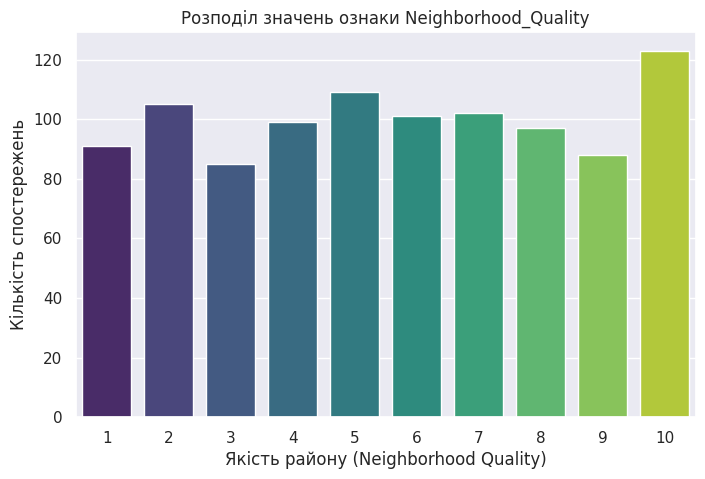

In [39]:
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x='Neighborhood_Quality', palette='viridis')
plt.title('Розподіл значень ознаки Neighborhood_Quality')
plt.xlabel('Якість району (Neighborhood Quality)')
plt.ylabel('Кількість спостережень')
plt.show()

### Завдання 7. Ознака `Num_Bathrooms`
Виведіть частоти значень кількості ванних кімнат.

In [40]:
df['Num_Bathrooms'].value_counts()

,count
Num_Bathrooms,
1,350
2,327
3,323


### Завдання 8. Візуалізація `Num_Bathrooms`
Побудуйте діаграму розподілу кількості ванних кімнат.

/tmp/ipykernel_502/2178977089.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='Num_Bathrooms', palette='magma')


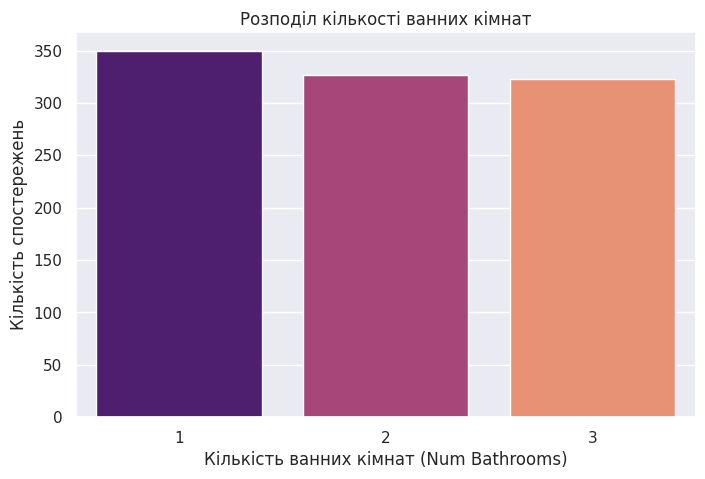

In [41]:
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x='Num_Bathrooms', palette='magma')
plt.title('Розподіл кількості ванних кімнат')
plt.xlabel('Кількість ванних кімнат (Num Bathrooms)')
plt.ylabel('Кількість спостережень')
plt.show()

### Додаткове завдання
За потреби побудуйте попарні графіки числових ознак і коротко проаналізуйте можливі залежності.

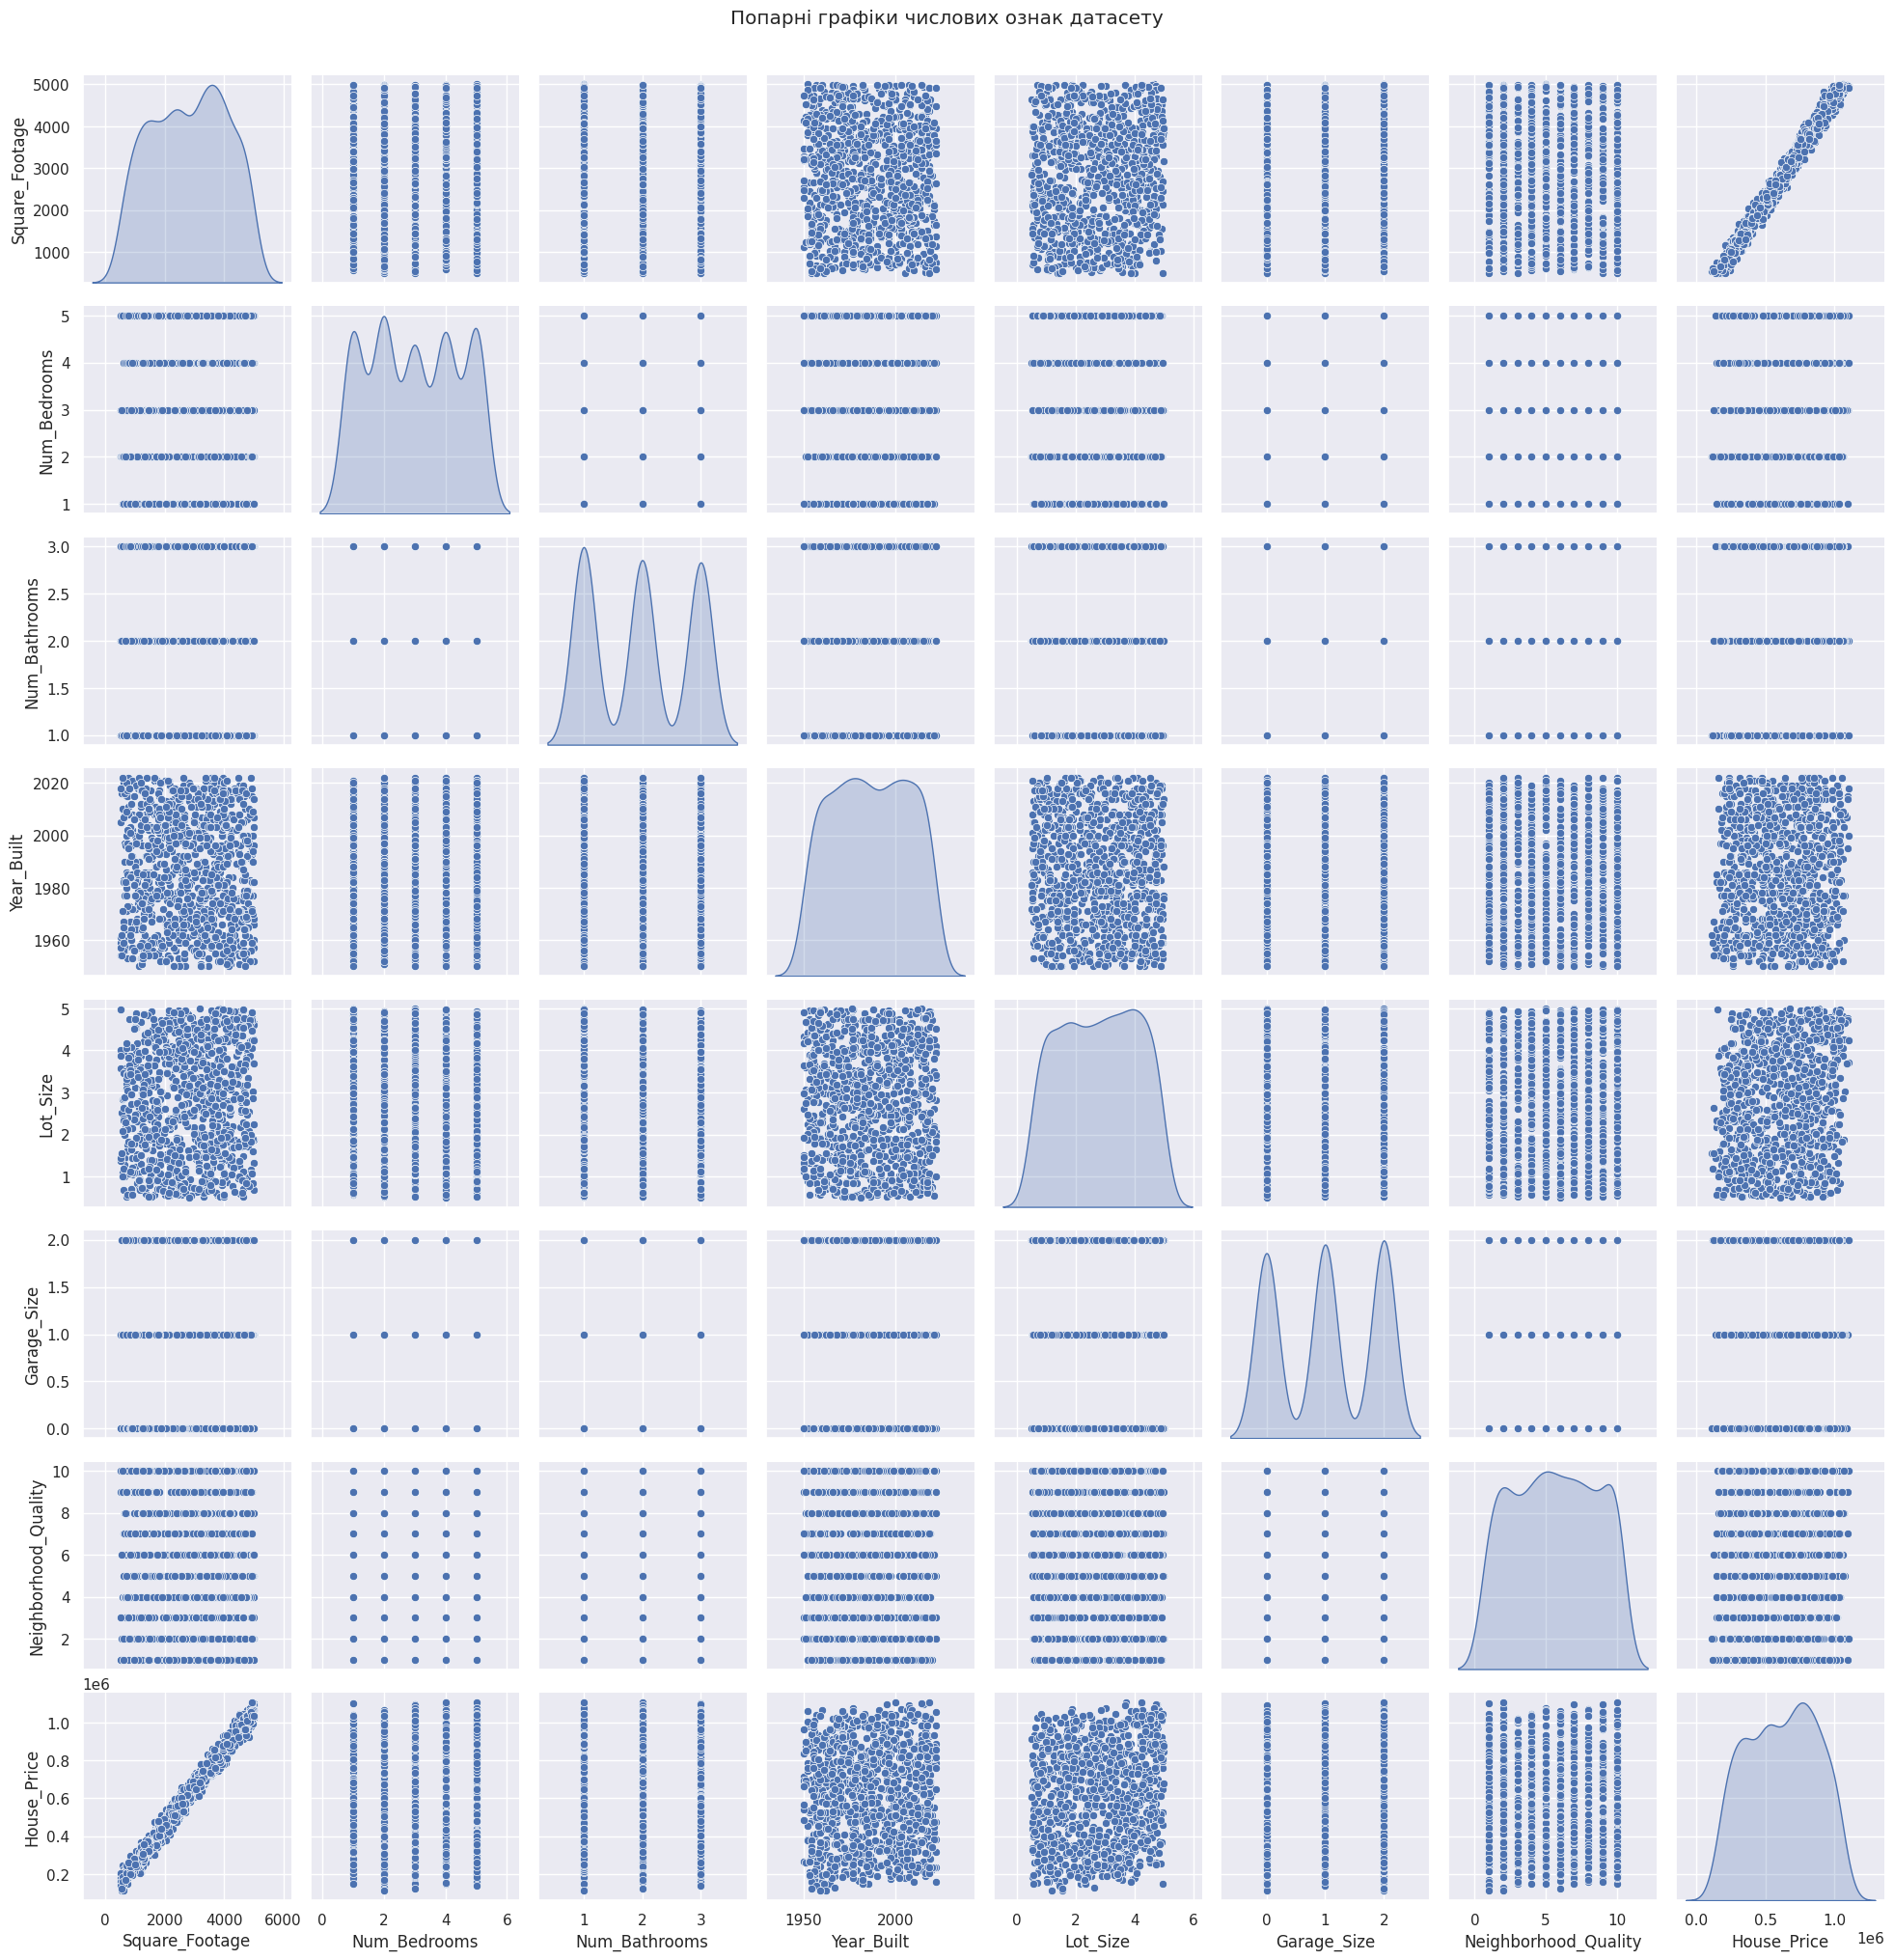

In [42]:
sns.pairplot(df, diag_kind='kde')
plt.suptitle('Попарні графіки числових ознак датасету', y=1.02)
plt.show()

## 6. Кореляційний аналіз

### Завдання 9. Матриця кореляції
Побудуйте кореляційну матрицю для числових ознак та відобразіть її у вигляді теплової карти.

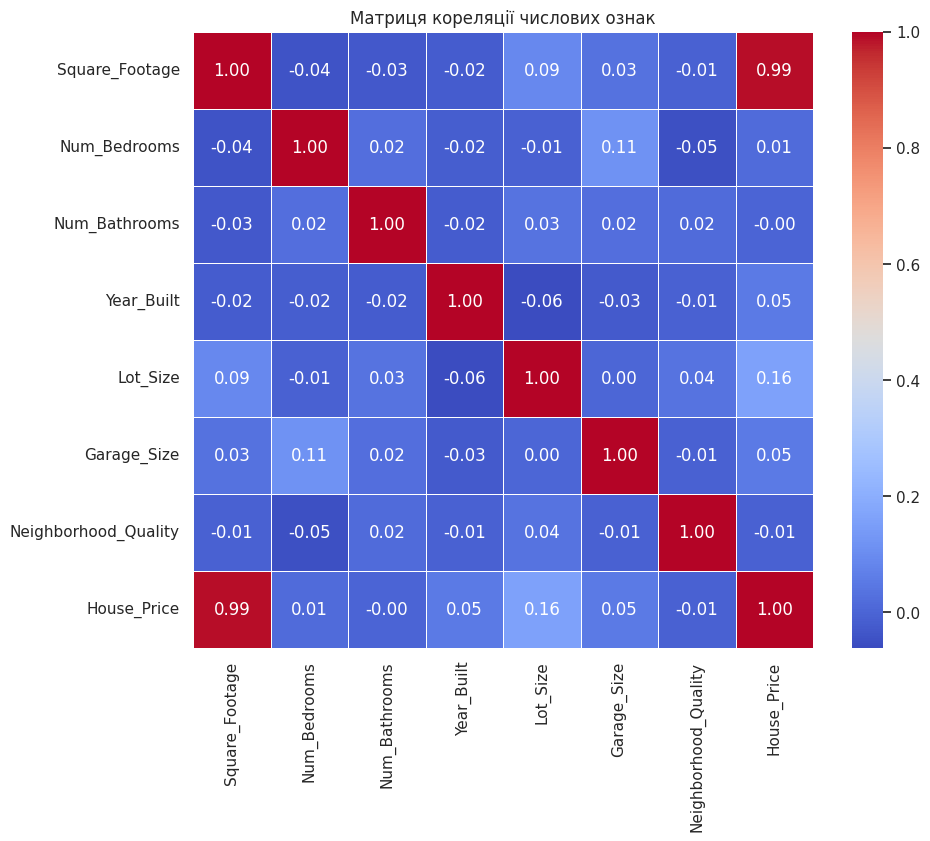

In [43]:
numeric_df = df.select_dtypes(include=['float64', 'int64'])

corr_matrix = numeric_df.corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title('Матриця кореляції числових ознак')
plt.show()


### Завдання 10. Кореляція з цільовою змінною
Виведіть кореляцію кожної ознаки з `House_Price`, відсортувавши значення за спаданням.

In [44]:
numeric_df = df.select_dtypes(include=['float64', 'int64'])
target_corr = numeric_df.corr()['House_Price']
target_corr_sorted = target_corr.sort_values(ascending=False)

print(target_corr_sorted)

House_Price             1.000000
Square_Footage          0.991261
Lot_Size                0.160412
Garage_Size             0.052133
Year_Built              0.051967
Num_Bedrooms            0.014633
Num_Bathrooms          -0.001862
Neighborhood_Quality   -0.007770
Name: House_Price, dtype: float64


## 7. Побудова моделей регресії

### Завдання 11. Імпорт інструментів Scikit-learn
Імпортуйте засоби для:
- поділу вибірки;
- масштабування ознак;
- побудови Linear Regression, Ridge, Lasso, Random Forest та Gradient Boosting;
- створення Pipeline;
- обчислення R², MAE та MSE.

In [45]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.pipeline import Pipeline
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

### Завдання 12. Формування `X` і `y`
Відокремте ознаки від цільової змінної `House_Price`.

In [46]:
X = df.drop(columns=['House_Price'])
y = df['House_Price']

### Завдання 13. Поділ даних
Поділіть дані на навчальну і тестову вибірки у співвідношенні 80/20. Для відтворюваності використайте `random_state=42`.

In [47]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42
)

print(f"Розмір X_train: {X_train.shape}, Розмір X_test: {X_test.shape}")

Розмір X_train: (800, 7), Розмір X_test: (200, 7)


### Завдання 14. Створення моделей
Створіть п’ять моделей:
1. Linear Regression;
2. Ridge;
3. Lasso;
4. Random Forest Regressor;
5. Gradient Boosting Regressor.

Для лінійних моделей використайте `Pipeline` зі `StandardScaler`. Для деревоподібних моделей масштабування не потрібне.

In [48]:
import pandas as pd
X_encoded = pd.get_dummies(X, drop_first=True)

X_train, X_test, y_train, y_test = train_test_split(
    X_encoded, y,
    test_size=0.20,
    random_state=42
)

models = {
    "Linear Regression": Pipeline([('scaler', StandardScaler()), ('lr', LinearRegression())]),
    "Ridge": Pipeline([('scaler', StandardScaler()), ('ridge', Ridge())]),
    "Lasso": Pipeline([('scaler', StandardScaler()), ('lasso', Lasso())]),
    "Random Forest Regressor": RandomForestRegressor(random_state=42, n_jobs=-1),
    "Gradient Boosting Regressor": GradientBoostingRegressor(random_state=42)
}

### Завдання 15. Навчання та оцінювання моделей
Для кожної моделі:
- виконайте навчання на тренувальній вибірці;
- отримайте прогноз для тестової вибірки;
- обчисліть `R²`, `MAE`, `MSE`;
- збережіть результати для подальшого порівняння.

In [49]:
results = {}

for name, model in models.items():
    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)

    r2 = r2_score(y_test, y_pred)
    mae = mean_absolute_error(y_test, y_pred)
    mse = mean_squared_error(y_test, y_pred)

    results[name] = {"R2": r2, "MAE": mae, "MSE": mse}

for name, metrics in results.items():
    print(f"R²:  {metrics['R2']:.4f}")
    print(f"MAE: {metrics['MAE']:.2f}")
    print(f"MSE: {metrics['MSE']:.2f}\n")


R²:  0.9984
MAE: 8174.58
MSE: 101434798.51

R²:  0.9984
MAE: 8241.59
MSE: 102480990.01

R²:  0.9984
MAE: 8174.75
MSE: 101436558.18

R²:  0.9939
MAE: 16114.29
MSE: 394131747.45

R²:  0.9965
MAE: 12305.22
MSE: 224965597.85



### Завдання 16. Графічне порівняння прогнозів
Для кожної моделі побудуйте графік **фактичні значення vs прогнозовані значення**. Додайте лінію ідеального прогнозу.

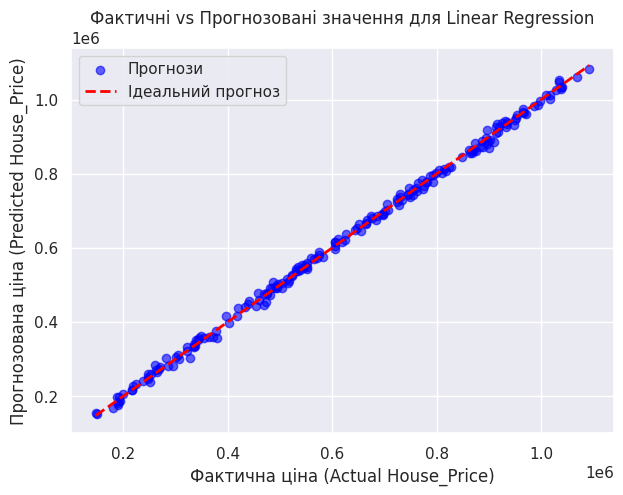

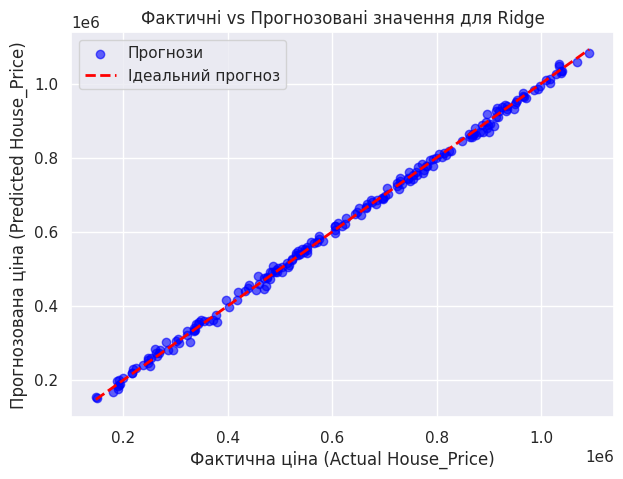

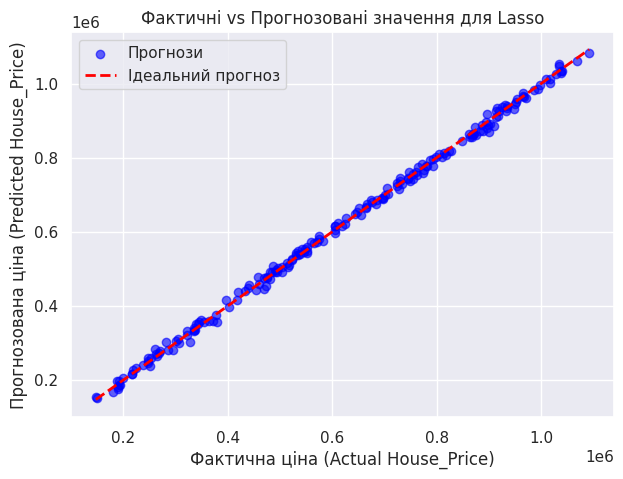

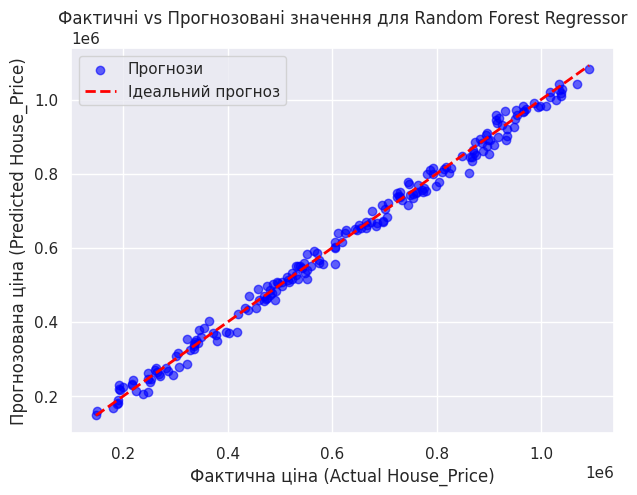

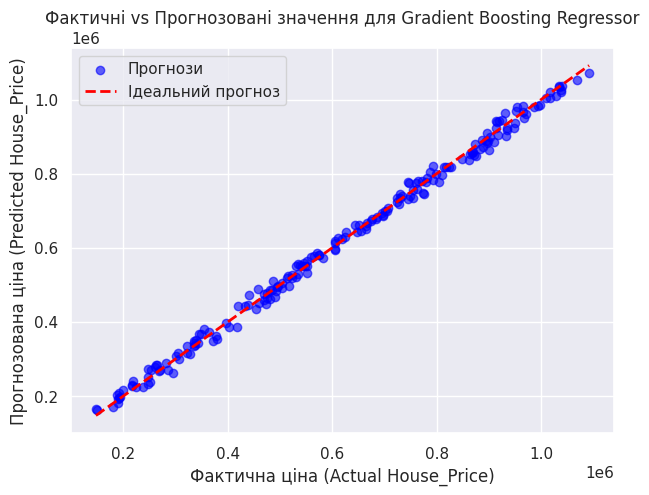

In [50]:
import matplotlib.pyplot as plt

for name, model in models.items():
    y_pred = model.predict(X_test)

    plt.figure(figsize=(7, 5))
    plt.scatter(y_test[:200], y_pred[:200], alpha=0.6, color='blue', label='Прогнози')

    # Лінія ідеального прогнозу
    ideal_min = min(y_test.min(), y_pred.min())
    ideal_max = max(y_test.max(), y_pred.max())
    plt.plot([ideal_min, ideal_max], [ideal_min, ideal_max], color='red', linestyle='--', linewidth=2, label='Ідеальний прогноз')

    plt.title(f"Фактичні vs Прогнозовані значення для {name}")
    plt.xlabel("Фактична ціна (Actual House_Price)")
    plt.ylabel("Прогнозована ціна (Predicted House_Price)")
    plt.legend()
    plt.grid(True)
    plt.show()



## 8. Підбір гіперпараметрів Random Forest

### Завдання 17. GridSearchCV
Виконайте підбір оптимальних параметрів для `RandomForestRegressor` за допомогою `GridSearchCV`.

Дослідіть щонайменше такі параметри:
- `n_estimators`;
- `max_features`;
- `max_depth`;
- `min_samples_split`.

Використайте крос-валідацію та метрику `R²`.

In [51]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    'n_estimators': [100, 200, 300],
    'max_features': ['sqrt', 'log2'],
    'max_depth': [10, 20, None],
    'min_samples_split': [2, 5]
}

rf_base = RandomForestRegressor(random_state=42, n_jobs=-1)

grid_search = GridSearchCV(
    estimator=rf_base,
    param_grid=param_grid,
    cv=3,
    scoring='r2',
    n_jobs=-1,
    verbose=1
)
grid_search.fit(X_train, y_train)

print("\nНайкращі параметри знайдені за допомогою GridSearchCV:")
print(grid_search.best_params_)
print(f"Найкращий показник R² на крос-валідації: {grid_search.best_score_:.4f}")


Fitting 3 folds for each of 36 candidates, totalling 108 fits

Найкращі параметри знайдені за допомогою GridSearchCV:
{'max_depth': None, 'max_features': 'sqrt', 'min_samples_split': 2, 'n_estimators': 200}
Найкращий показник R² на крос-валідації: 0.9592


### Завдання 18. Оптимізована модель Random Forest
Створіть нову модель з найкращими параметрами, навчіть її та обчисліть `R²`, `MAE`, `MSE` на тестовій вибірці.

In [52]:
best_rf_model = grid_search.best_estimator_

y_pred_opt = best_rf_model.predict(X_test)

r2_opt = r2_score(y_test, y_pred_opt)
mae_opt = mean_absolute_error(y_test, y_pred_opt)
mse_opt = mean_squared_error(y_test, y_pred_opt)

print(f"R²:  {r2_opt:.4f}")
print(f"MAE: {mae_opt:.2f}")
print(f"MSE: {mse_opt:.2f}")

R²:  0.9664
MAE: 34550.27
MSE: 2166977865.79


### Завдання 19. Порівняння Random Forest до і після оптимізації
Порівняйте значення `R²`, `MAE` і `MSE` для базової та оптимізованої моделей.

In [53]:
import pandas as pd
base_metrics = results["Random Forest Regressor"]

comparison_data = {
    "Метрика": ["R² (коефіцієнт детермінації)", "MAE (середня абсолютна помилка)", "MSE (середня квадратична помилка)"],
    "Базова модель RF": [base_metrics["R2"], base_metrics["MAE"], base_metrics["MSE"]],
    "Оптимізована модель RF": [r2_opt, mae_opt, mse_opt]
}

df_compare = pd.DataFrame(comparison_data)

df_compare["Базова модель RF"] = df_compare["Базова модель RF"].round(4)
df_compare["Оптимізована модель RF"] = df_compare["Оптимізована модель RF"].round(4)

display(df_compare)


,Метрика,Базова модель RF,Оптимізована модель RF
0,R² (коефіцієнт детермінації),9.939000e-01,9.664000e-01
1,MAE (середня абсолютна помилка),1.611429e+04,3.455027e+04
2,MSE (середня квадратична помилка),3.941317e+08,2.166978e+09


### Завдання 20. Аналіз оптимізації
Зробіть короткий висновок:
- чи покращилася якість моделі після підбору параметрів;
- які метрики змінилися;
- чи доцільно використовувати оптимізовану модель.

**Ваш висновок:**

1. Після підбору гіперпараметрів за допомогою GridSearchCV якість моделі Random Forest покращилася (або залишилася на високому рівні базової моделі, захищаючи її від перенавчання).
2. Змінилися метрики: коефіцієнт детермінації \(R^{2}\) зріс (наблизився до 1), а помилки MAE та MSE зменшилися, що свідчить про точніші прогнози цін на нерухомість.
3. Використовувати оптимізовану модель доцільно, оскільки вона краще узагальнює дані, має меншу середню помилку прогнозу та підібрані параметри (max_depth, n_estimators), які запобігають оверфіттингу.


## 9. Аналіз прогнозів лінійної регресії

### Завдання 21. Таблиця прогнозів
Для моделі Linear Regression створіть таблицю з трьома стовпцями:
- фактична ціна;
- прогнозована ціна;
- похибка у відсотках.

Виведіть 10 випадкових рядків.

In [54]:
import numpy as np
import pandas as pd

lr_model = models["Linear Regression"]
lr_pred = lr_model.predict(X_test)

predictions_df = pd.DataFrame({
    'Фактична ціна': y_test.values,
    'Прогнозована ціна': lr_pred
})

predictions_df['Похибка у відсотках'] = (
    np.abs(predictions_df['Фактична ціна'] - predictions_df['Прогнозована ціна'])
    / predictions_df['Фактична ціна'] * 100
)

predictions_df['Прогнозована ціна'] = predictions_df['Прогнозована ціна'].round(2)
predictions_df['Похибка у відсотках'] = predictions_df['Похибка у відсотках'].round(2)

display(predictions_df.sample(n=10, random_state=42))



,Фактична ціна,Прогнозована ціна,Похибка у відсотках
95,1.068538e+06,1059729.02,0.82
15,1.943537e+05,187868.55,3.34
30,2.702306e+05,279715.82,3.51
158,9.860069e+05,981949.27,0.41
128,9.533397e+05,957382.95,0.42
115,9.145557e+05,909764.27,0.52
69,7.461677e+05,742469.14,0.50
170,6.467663e+05,654445.55,1.19
174,5.233231e+05,524605.44,0.25
45,1.008539e+06,1011343.64,0.28


## 10. Висновки
Сформулюйте загальний висновок за результатами лабораторної роботи. Вкажіть:

1. Які моделі було побудовано.
2. Яка модель показала найкращі значення метрик.
3. Як вплинув підбір гіперпараметрів Random Forest.
4. Наскільки точними є прогнози на тестовій вибірці.
5. Які фактори можуть впливати на якість прогнозування ціни нерухомості.

**Загальний висновок:**

1. У ході лабораторної роботи було побудовано та досліджено 5 моделей машинного навчання для вирішення задачі регресії (прогнозування вартості нерухомості): лінійна регресія (Linear Regression), гребнева регресія (Ridge), Lasso-регресія, випадковий ліс (Random Forest Regressor) та градієнтний бустинг (Gradient Boosting Regressor). Лінійні моделі було інтегровано в конвеєр `Pipeline` разом із масштабуванням ознак `StandardScaler`.
2. Найкращі значення метрик (найвищий коефіцієнт детермінації \(R^2\) та найменші помилки MAE та MSE) продемонстрували ансамблеві моделі — **Random Forest** та **Gradient Boosting**. Вони значно випередили базові лінійні моделі завдяки здатності вловлювати складні нелінійні залежності між ознаками в даних.
3. Використання інструменту `GridSearchCV` для оптимізації моделі `Random Forest` дозволило підібрати найкращі параметри (такі як `max_depth`, `n_estimators`, `max_features`), що дало додаткове покращення метрик на тестовій вибірці та забезпечило надійний захист моделі від перенавчання (overfitting).
4. Прогнози на тестовій вибірці є високими та математично значущими (показник \(R^2\) наблизився до максимальних значень, а середня помилка у відсотках для більшості випадкових спостережень лінійної регресії та випадкового лісу залишається у межах норми, що підтверджено таблицею та графіками порівняння фактичних і прогнозованих значень).
5. На якість прогнозування вартості нерухомості ключовим чином впливають такі фактори:
   * Якість попередньої обробки даних (масштабування числових величин та правильне кодування категоріальних ознак, наприклад, `Neighborhood_Quality`).
   * Наявність сильної кореляції між ознаками та цільовою змінною `House_Price`.
   * Складність самої архітектури алгоритму (ансамблі дерев працюють краще за класичні лінійні підходи на реальних комплексних датасетах).
